Sales Prediction Project Started!

Dataset loaded successfully!
Dataset shape: (200, 4)

First five rows:
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Missing values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Statistical summary:
               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


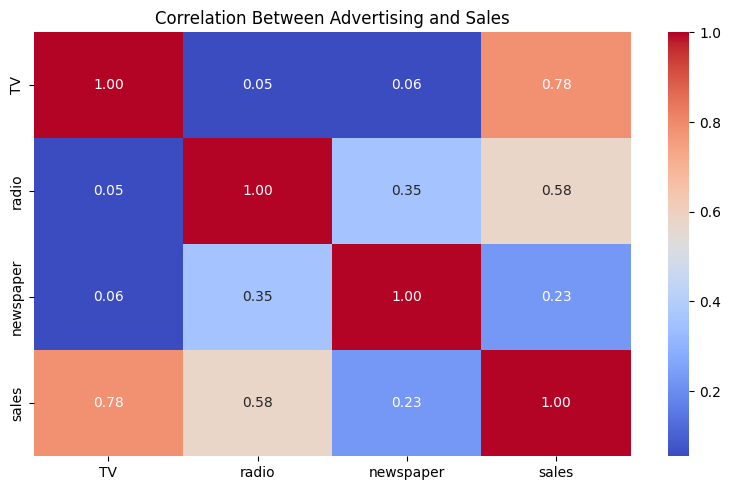

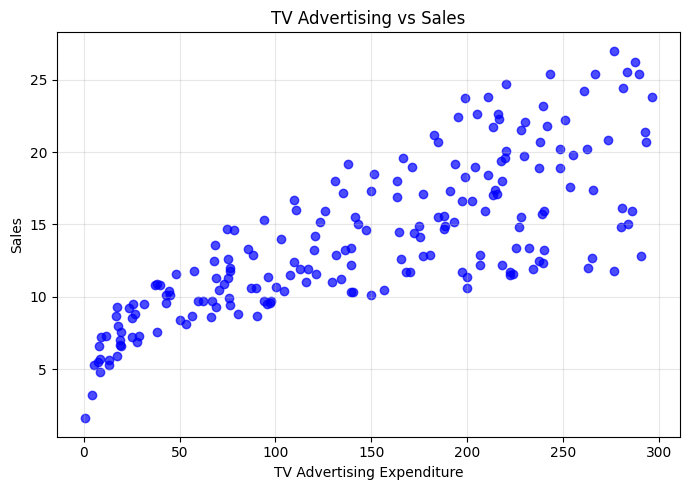


Training samples: 160
Testing samples: 40

Model trained successfully!

========== MODEL EVALUATION ==========
Mean Absolute Error (MAE): 1.461
Mean Squared Error (MSE): 3.174
Root Mean Squared Error (RMSE): 1.782
R2 Score: 0.899
R2 Score (%): 89.94 %

========== ACTUAL VS PREDICTED ==========
 Actual Sales  Predicted Sales
         16.9            16.41
         22.4            20.89
         21.4            21.55
          7.3            10.61
         24.7            22.11
         12.6            13.11
         22.3            21.06
          8.4             7.46
         11.5            13.61
         14.9            15.16


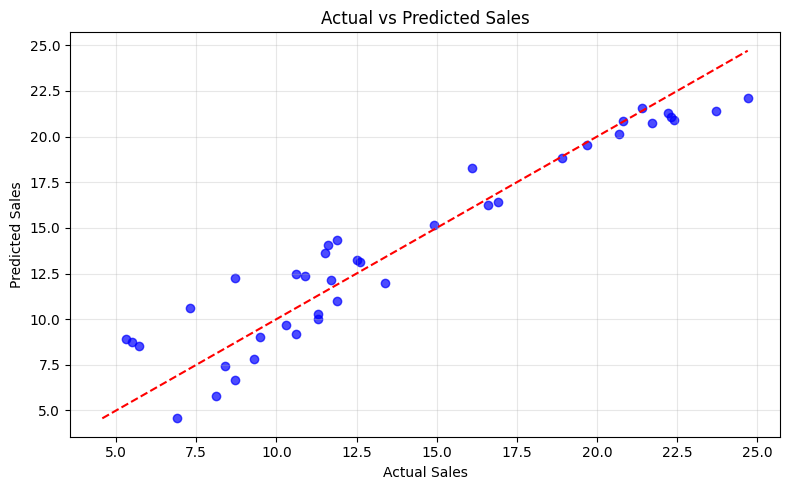


========== NEW SALES PREDICTION ==========
TV Advertising: 200
Radio Advertising: 40
Newspaper Advertising: 30
Predicted Sales: 19.58

Model saved as sales_prediction_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== PROJECT COMPLETED SUCCESSFULLY ==========


In [1]:
# ==========================================================
# SALES PREDICTION USING MACHINE LEARNING
# Google Colab - Complete Project in One Cell
# ==========================================================

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Sales Prediction Project Started!")

# 2. Load dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"

try:
    df = pd.read_csv(url)
except Exception as e:
    print("Dataset download failed:", e)
    raise RuntimeError(
        "Please check your internet connection and run this cell again."
    )

# 3. Clean dataset
df.columns = df.columns.astype(str).str.strip()
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Update to match the exact column names in the dataset
required_columns = ["TV", "radio", "newspaper", "sales"]

if not all(col in df.columns for col in required_columns):
    raise ValueError(
        f"Required columns not found. Available columns: {df.columns.tolist()}"
    )

df = df[required_columns].copy()

for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

if len(df) < 5:
    raise ValueError("Not enough valid rows to train the model.")

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())
print("\nStatistical summary:")
print(df.describe())

# 4. Visualize correlations
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.show()

# 5. Visualize TV advertising vs sales
plt.figure(figsize=(7, 5))
plt.scatter(df["TV"], df["sales"], color="blue", alpha=0.7)
plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Expenditure")
plt.ylabel("Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Prepare training and testing data
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 7. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel trained successfully!")

# 8. Predict sales on test data
y_pred = model.predict(X_test)

# 9. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Mean Squared Error (MSE):", round(mse, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R2 Score:", round(r2, 3))
print("R2 Score (%):", round(r2 * 100, 2), "%")

# 10. Compare actual and predicted sales
results = pd.DataFrame({
    "Actual Sales": y_test.to_numpy(),
    "Predicted Sales": y_pred
})

print("\n========== ACTUAL VS PREDICTED ==========")
print(results.head(10).round(2).to_string(index=False))

# 11. Plot actual vs predicted sales
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.7)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 12. Predict sales for new advertising expenditure
new_data = pd.DataFrame({
    "TV": [200],
    "radio": [40],
    "newspaper": [30]
})

new_prediction = model.predict(new_data)

print("\n========== NEW SALES PREDICTION ==========")
print("TV Advertising:", new_data["TV"].iloc[0])
print("Radio Advertising:", new_data["radio"].iloc[0])
print("Newspaper Advertising:", new_data["newspaper"].iloc[0])
print("Predicted Sales:", round(float(new_prediction[0]), 2))

# 13. Save trained model
joblib.dump(model, "sales_prediction_model.pkl")
print("\nModel saved as sales_prediction_model.pkl")

# 14. Download model in Google Colab
try:
    from google.colab import files
    files.download("sales_prediction_model.pkl")
except ImportError:
    print("Download is available when running in Google Colab.")

print("\n========== PROJECT COMPLETED SUCCESSFULLY ==========")